# PartB - Fig. XX  (a, b; portrait): glacier model differences in steady-state mass and in climate scenario sensitivity

Difference of every glacier model to the median model in every RGI region (Global on top, then the regions sorted by their 2020 glacier mass as in GMIP3-comm Fig. 2), for the temperature bin 2.0°C to 4.0°C. One row per glacier model: **dot = median** over the 31 climate scenarios, **line = likely range** (17th to 83rd percentile of the 31 climate scenarios). The figure is made for a width of 8.3cm
- `a`: difference of the steady-state mass to the median model
- `b`: change of that difference relative to the climate of 1995-2014 (climate scenario sensitivity)

We also looked at the other temperature bins, but don't show them in the manuscript.

In [2]:
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt

In [3]:
plt.rcParams["pdf.use14corefonts"] = False  # don't convert text to path
plt.rcParams['pdf.fonttype'] = 42  # keep the text editable in the pdf

## Settings

In [4]:
fn_steady_state = 'PartB_data/steady_state_relative_volume_change.csv'
temp_bin = [2.0, 4.0]            # global warming bin in °C
# temp_bin = [4.0, 7.0]            # global warming bin in °C
# temp_bin = [-0.1, 2.0]            # global warming bin in °C

likely_range = [17, 83]          # percentiles over the climate scenarios
ref_period = '1995-2014_hist'    # reference climate for the climate scenario sensitivity (Fig. 2)

# panels from left to right: 'a' (steady-state mass), 'b' (climate scenario sensitivity); ['b] 
panel_order = ['a', 'b']

# difference to which median?
#  'all_models': median of all glacier models in the region (= the existing 'delta ... to median model' columns, as in the first versions of Fig. 1 and 2)
#  'global4': median of the four global models only (the same models in every region)
reference = 'all_models'

fig_width_cm, fig_height_cm = 8.3, 17   # one-column figure (before: 11.5, 19 )
x_lims = {'a': (-40, 65), 'b': (-65, 50)}      # % points
x_ticks = {'a': np.arange(-40, 61, 20), 'b': np.arange(-60, 41, 20)}
fs = 6                                   # smallest font size in the figure

fig_dir = 'figures_partB/glacier_model_ss_differences/'
os.makedirs(fig_dir, exist_ok=True)

## Names, colours and order of the regions

In [5]:
reg_names = {'All': 'Global', '01': 'Alaska', '02': 'W Canada & US', '03': 'Arctic Canada N', '04': 'Arctic Canada S',
             '05': 'Greenland Periphery', '06': 'Iceland', '07': 'Svalbard & Jan Mayen', '08': 'Scandinavia',
             '09': 'Russian Arctic', '10': 'North Asia', '11': 'Central Europe', '12': 'Caucasus & Middle East',
             '13': 'Central Asia', '14': 'South Asia W', '15': 'South Asia E', '16': 'Low Latitudes',
             '17': 'Southern Andes', '18': 'New Zealand', '19': 'Subantarctic & Antarctic Islands'}
# names with a line break where a name is long
reg_names_lines = dict(reg_names)
reg_names_lines.update({'05': 'Greenland\nPeriphery', '07': 'Svalbard &\nJan Mayen', '12': 'Caucasus &\nMiddle East',
                        '19': 'Subantarctic &\nAntarctic Islands'})

# Global on top, then sorted by the 2020 glacier mass (descending) as in Fig. 2 of GMIP3-comm
reg_order = ['All', '19', '03', '01', '05', '09', '04', '07', '17', '06', '13', '14', '02', '15', '08', '10', '11', '16', '18', '12']

global_models = ['PyGEM-OGGM', 'GloGEMflow', 'OGGM', 'GLIMB']
regional_models = ['GloGEMflow3D', 'Kraaijenbrink', 'GO', 'CISM2']
model_names_csv = {'PyGEM-OGGM_v13': 'PyGEM-OGGM', 'OGGM_v16': 'OGGM'}   # names in the csv file, all others are the same
dict_model_col = {'PyGEM-OGGM': '#5fb0e1', 'GloGEMflow': '#d18c14', 'OGGM': '#ca79bc', 'GLIMB': '#fab1e5',
                  'GloGEMflow3D': '#0f9373', 'Kraaijenbrink': '#c46011', 'GO': '#e5d73d', 'CISM2': '#562e10'}

## 1. Prepare the data

In [6]:
pd_ss = pd.read_csv(fn_steady_state, index_col=0)
pd_ss['model'] = pd_ss.model_author.replace(model_names_csv)
pd_ss['reg'] = pd_ss.rgi_reg.replace({'Global': 'All'})

rc = 'relative volume change (in %)'
dc = 'delta relative volume change (in %, to median model)'
dc2 = 'delta relative volume change (in %, to median model, relative to ref period )'

# difference of every model to the reference (a) and its change relative to the reference climate (b)
if reference == 'all_models_stored':
    # OLD: stored delta columns of PartB_3 (median of the absolute volumes divided by the median 2020 volume,
    # i.e. not the median of the plotted relative values)
    pd_ss['a'] = pd_ss[dc]
    pd_ss['b'] = pd_ss[dc2]
else:
    if reference == 'all_models':
        # median of the relative values (% of each glacier model's own 2020 mass) of all glacier models in the region
        ref = pd_ss.groupby(['reg', 'gcm', 'period_scenario'])[rc].median()
    else:   # 'global4'
        ref = pd_ss.loc[pd_ss.model.isin(global_models)].groupby(['reg', 'gcm', 'period_scenario'])[rc].median()
    pd_ss = pd_ss.join(ref.rename('ref'), on=['reg', 'gcm', 'period_scenario'])
    pd_ss['a'] = pd_ss[rc] - pd_ss['ref']
    d_ref_period = pd_ss.loc[pd_ss.period_scenario == ref_period].set_index(['reg', 'model', 'gcm'])['a']
    pd_ss = pd_ss.join(d_ref_period.rename('a_ref_period'), on=['reg', 'model', 'gcm'])
    pd_ss['b'] = pd_ss['a'] - pd_ss['a_ref_period']

pd_bin = pd_ss.loc[(pd_ss.temp_ch_ipcc >= temp_bin[0]) & (pd_ss.temp_ch_ipcc <= temp_bin[1])]
n_scen = len(pd_bin.groupby(['gcm', 'period_scenario']))
if temp_bin[1] == 4.0:
    np.testing.assert_allclose(len(pd_bin.groupby(['gcm', 'period_scenario'])), 31)


# median and likely range over the climate scenarios
pd_sums = {}
for p in ['a', 'b']:
    g = pd_bin.groupby(['reg', 'model'])[p]
    pd_sums[p] = pd.DataFrame({'med': g.median(), 'lo': g.quantile(likely_range[0] / 100),
                               'hi': g.quantile(likely_range[1] / 100)})
    print(p, pd_sums[p].shape, '| range of the likely ranges:', np.round(pd_sums[p].lo.min(),1),
          'to', np.round(pd_sums[p].hi.max(),1))

a (96, 3) | range of the likely ranges: -33.6 to 60.7
b (96, 3) | range of the likely ranges: -60.5 to 47.0


**Check:** the order of the regions. The 2020 volume in the csv file (volume divided by relative volume change) gives the same order as GMIP3-comm Fig. 2:

In [7]:
pd_chk = pd_ss.loc[pd_ss.reg != 'All'].copy()
pd_chk['v0'] = pd_chk.volume_m3 / (pd_chk[rc] / 100)
v0_reg = pd_chk.groupby('reg').v0.median()
print('order from the csv file  :', list(v0_reg.sort_values(ascending=False).index))
print('order used in the figure :', reg_order[1:])
print('share of the global volume (%):', (100 * v0_reg / v0_reg.sum()).round(1).reindex(reg_order[1:]).to_dict())

order from the csv file  : ['19', '03', '01', '05', '09', '04', '07', '17', '06', '13', '14', '02', '15', '08', '10', '11', '16', '18', '12']
order used in the figure : ['19', '03', '01', '05', '09', '04', '07', '17', '06', '13', '14', '02', '15', '08', '10', '11', '16', '18', '12']
share of the global volume (%): {'19': 30.1, '03': 18.1, '01': 11.8, '05': 9.8, '09': 9.4, '04': 5.2, '07': 4.8, '17': 3.2, '06': 2.3, '13': 2.0, '14': 1.8, '02': 0.6, '15': 0.5, '08': 0.2, '10': 0.1, '11': 0.1, '16': 0.1, '18': 0.0, '12': 0.0}


## 2. The figure

In [8]:
x_ticks

{'a': array([-40, -20,   0,  20,  40,  60]),
 'b': array([-60, -40, -20,   0,  20,  40])}

31 climate scenarios between 2.0°C and 4.0°C global warming


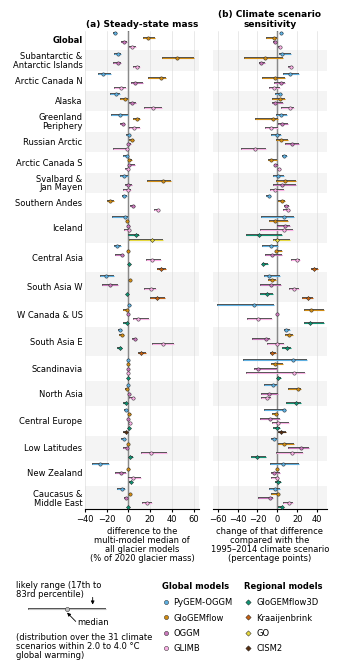

In [9]:
import matplotlib.patheffects as pe      # thin dark outline around the likely-range lines

n_panels = len(panel_order)
if n_panels == 1:
    boxes = [(0.285, 0.70)]
else:
    # CL: in cm: column of the region names, gap between the panels, right margin
    lab_w_cm, gap_cm, right_cm = 1.9, 0.35, 0.25
    panel_w_cm = (fig_width_cm - lab_w_cm - gap_cm - right_cm) / 2
    boxes = [(lab_w_cm / fig_width_cm, panel_w_cm / fig_width_cm),
             ((lab_w_cm + panel_w_cm + gap_cm) / fig_width_cm, panel_w_cm / fig_width_cm)]      # (left, width) of the panels
ax_bottom, ax_height = 0.225, 0.715              # CL: in figure fractions (room for the legend and the 4-line x labels)
lw_rng, lw_out, ms_o, ms_d = 0.8, 1.3, 2.4, 2.1    # CL: printed line widths / marker sizes (rows are ~3 pt apart)
fig = plt.figure(figsize=(fig_width_cm / 2.54, fig_height_cm / 2.54))

# one row per glacier model, the four global models first and then the regional models, with a gap between the regions
gap = 0.5      # CL: 0.5 instead of 0.7 rows between the regions (height)
rows = []
y = 0
reg_centres = []
reg_spans = []
for i, reg in enumerate(reg_order):
    models_reg = [m for m in global_models + regional_models if (reg, m) in pd_sums['a'].index]
    reg_spans.append((y - 0.5 - gap / 2, y + len(models_reg) - 0.5 + gap / 2, i))
    for k, m in enumerate(models_reg):
        rows.append((reg, m, y + k))
    reg_centres.append((y + (len(models_reg) - 1) / 2, reg))
    y = y + len(models_reg) + gap
y_max = y - gap - 0.5

titles = {'a': 'Steady-state mass', 'b': 'Climate scenario\nsensitivity'}     # CL: line break, panel (b) is only 2.9 cm wide
if reference == 'all_models':
    xlabels = {'a': 'difference to the\nmulti-model median of\nall glacier models\n(% of 2020 glacier mass)',      # CL: wrapped
               'b': 'change of that difference\ncompared with the\n1995–2014 climate scenario\n(percentage points)'}
else:
    xlabels = {'a': 'difference to the\nmulti-model median\n(% of 2020 glacier mass)',
               'b': 'change of that difference\ncompared with the\n1995–2014 climate scenario\n(percentage points)'}

axes = []
for i_p, p in enumerate(panel_order):
    #ax = fig.add_axes([boxes[i_p][0], 0.185, boxes[i_p][1], 0.745])
    ax = fig.add_axes([boxes[i_p][0], ax_bottom, boxes[i_p][1], ax_height])
    axes.append(ax)
    for y_lo, y_hi, i in reg_spans:    # light background for every second region
        if i % 2 == 1:
            ax.axhspan(y_lo, y_hi, color='0.955', lw=0, zorder=0)
    for reg, m, y_row in rows:
        r = pd_sums[p].loc[(reg, m)]
        marker = 'o' if m in global_models else 'D'
        ax.plot([r.lo, r.hi], [y_row] * 2, color=dict_model_col[m], lw=lw_rng, solid_capstyle='butt', zorder=2,
                path_effects=[pe.Stroke(linewidth=lw_out, foreground='0.25'), pe.Normal()])
        ax.plot([r.med], [y_row], marker, ms=ms_o if marker == 'o' else ms_d,
                mfc=dict_model_col[m], mec='0.15', mew=0.35, zorder=3)
    ax.set_ylim(y_max, -0.5)
    ax.set_xlim(*x_lims[p])
    ax.axvline(0, color='0.15', lw=0.9, zorder=1)
    ax.set_yticks([])
    ax.set_xticks(x_ticks[p])
    ax.tick_params(axis='x', labelsize=fs, length=2, pad=1.5)
    ax.grid(axis='x', color='0.85', lw=0.4, zorder=0)
    for sp in ['top', 'right', 'left']:
        ax.spines[sp].set_visible(False)
    ax.set_xlabel(xlabels[p], fontsize=fs, labelpad=2, linespacing=1.0)      # CL: fs instead of fs + 0.5 (space)
    if n_panels > 1:
        ax.set_title(f'({chr(97 + i_p)}) {titles[p]}', fontsize=fs + 0.5, fontweight='bold', pad=3)

# names of the regions (without the RGI region numbers)
for y_c, reg in reg_centres:
    name = reg_names_lines[reg]
    axes[0].text(-0.02, y_c, name, transform=axes[0].get_yaxis_transform(), ha='right', va='center',
                 fontsize=fs, fontweight='bold' if reg == 'All' else 'normal', linespacing=0.95)

# which climate scenarios?
#fig.text(0.5, 0.993, f'{n_scen} climate scenarios between {temp_bin[0]:.1f}\u00b0C and {temp_bin[1]:.1f}\u00b0C global warming',
#         fontsize=fs + 0.5, ha='center', va='top')
print( f'{n_scen} climate scenarios between {temp_bin[0]:.1f}\u00b0C and {temp_bin[1]:.1f}\u00b0C global warming')

# legend: dummy row with arrows, and the model names with their group as subtitle
# CL: rearranged for the 8.3 cm width, x in cm, all text at fs
ax_leg = fig.add_axes([0.0, 0.0, 1.0, 0.12])
ax_leg.set_xlim(0, fig_width_cm)
ax_leg.set_ylim(0, 1)
ax_leg.axis('off')
arrow = dict(arrowstyle='-|>', color='k', lw=0.6, shrinkA=0, shrinkB=0, mutation_scale=5)
outline = [pe.Stroke(linewidth=lw_out, foreground='0.25'), pe.Normal()]

x0_l, x1_l, y_l, x_med = 0.45, 2.45, 0.64, 1.45     # dummy likely range and median (cm)
ax_leg.plot([x0_l, x1_l], [y_l, y_l], color='0.75', lw=lw_rng, solid_capstyle='butt', path_effects=outline)
ax_leg.plot([x_med], [y_l], 'o', ms=3.0, mfc='0.75', mec='0.15', mew=0.35)
ax_leg.text(0.15, 0.99, f'likely range ({likely_range[0]}th to\n{likely_range[1]}rd percentile)', fontsize=fs, ha='left',
            va='top', linespacing=1.0)
ax_leg.annotate('', xy=(2.1, y_l + 0.05), xytext=(2.1, 0.78), arrowprops=arrow)
ax_leg.text(x_med + 0.25, 0.48, 'median', fontsize=fs, ha='left', va='center')
ax_leg.annotate('', xy=(x_med, y_l - 0.05), xytext=(x_med + 0.22, 0.48), arrowprops=arrow)
# CL: space between number and unit (Copernicus figure guidelines)
t0_str, t1_str = (f'{t:.1f}'.replace('-', '\u2212') for t in temp_bin)     # real minus sign
ax_leg.text(0.15, 0.01, f'(distribution over the {n_scen} climate\nscenarios within {t0_str} to {t1_str} \u00b0C\nglobal warming)',
            fontsize=fs, ha='left', va='bottom', linespacing=1.0)

x_g, x_r, y_0, dy = 3.85, 5.95, 0.72, 0.19         # CL: start of the two model columns (cm)
ax_leg.text(x_g, 0.93, 'Global models', fontsize=fs, fontweight='bold', va='center')
ax_leg.text(x_r, 0.93, 'Regional models', fontsize=fs, fontweight='bold', va='center')
for k, m in enumerate(global_models):
    ax_leg.plot([x_g + 0.1], [y_0 - dy * k], 'o', ms=3.0, mfc=dict_model_col[m], mec='0.15', mew=0.35)
    ax_leg.text(x_g + 0.3, y_0 - dy * k, m, fontsize=fs, va='center')
for k, m in enumerate(regional_models):
    ax_leg.plot([x_r + 0.1], [y_0 - dy * k], 'D', ms=2.7, mfc=dict_model_col[m], mec='0.15', mew=0.35)
    ax_leg.text(x_r + 0.3, y_0 - dy * k, m, fontsize=fs, va='center')

fn_out = f'{fig_dir}/manuscript_v0_steady_state_glacier_model_differences_portrait_{"_".join(panel_order)}_{reference}_temp_bin_{temp_bin[0]}_{temp_bin[1]}'
plt.savefig(fn_out + '.png', dpi=300)
plt.savefig(fn_out + '.pdf')
plt.show()

## Caption in LaTeX)

```latex
\begin{figure}[ht]
    \centering
    \includegraphics[width=8.3cm]{fig/manuscript_v0_steady_state_glacier_model_differences_portrait_a_b_all_models_temp_bin_2.0_4.0.png}
    \caption{Glacier model differences in steady-state glacier mass for climate scenarios with a global warming of 2.0 to 4.0\,$^{\circ}$C (31 climate scenarios), globally and for the 19 RGI regions. \textbf{(a)} Difference of each glacier model to the multi-model median of all glacier models available in a region (in \% of the 2020 glacier mass). \textbf{(b)} Climate scenario sensitivity, i.e.\ the difference in (a) minus the difference of the same glacier model under the 1995--2014 climate scenario of the same climate model (in percentage points; see Sect.~\ref{sec:differences}). Negative values in (b) indicate that a glacier model loses more mass than the multi-model median between the 1995--2014 climate scenario and a given climate scenario; values close to zero indicate that its difference to the multi-model median persists across climate scenarios. Dots (global glacier models) and diamonds (regional glacier models) show the median, and lines the likely range (17th to 83rd percentile), over the 31 climate scenarios. Global (top) is the sum over all regions of the four global glacier models; the regions are sorted by their 2020 glacier mass.}
\label{fig:app_gmip3_steady_state_model_differences}
```